# M1.3 · 订单簿与撮合机制

> 连续竞价的核心是限价单簿（LOB）：买卖订单按价格档位排队，新订单到达即与对手盘撮合。
> 本节用 micro_lab 的 OrderBook 实操挂单、撮合、撤单，并可视化订单簿。

## 一、订单簿结构

- 买盘（bid）：投资者愿意买入的价格和数量，最高买价为 best bid；
- 卖盘（ask）：愿意卖出的价格和数量，最低卖价为 best ask；
- 中间价 mid = (best bid + best ask)/2；报价价差 = best ask − best bid；
- 深度：各档位挂单量，反映流动性厚度。

## 二、构建订单簿并挂单

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from micro_lab.lob import OrderBook
ob = OrderBook()
# 卖方挂5档
for p, q in [(10.05, 300), (10.06, 250), (10.07, 400), (10.08, 200), (10.09, 350)]:
    ob.limit_order('SELL', p, q)
# 买方挂5档
for p, q in [(10.04, 280), (10.03, 220), (10.02, 380), (10.01, 260), (10.00, 320)]:
    ob.limit_order('BUY', p, q)
print('best bid=%s best ask=%s mid=%s spread=%.2f' %
      (ob.best_bid(), ob.best_ask(), ob.mid_price(), ob.quoted_spread()))
print('买5档:', ob.depth('bid'))
print('卖5档:', ob.depth('ask'))

best bid=10.04 best ask=10.05 mid=10.045 spread=0.01
买5档: [(10.04, 280), (10.03, 220), (10.02, 380), (10.01, 260), (10.0, 320)]
卖5档: [(10.05, 300), (10.06, 250), (10.07, 400), (10.08, 200), (10.09, 350)]


## 三、连续撮合：主动订单吃单

In [2]:
# 主动买单 600 股，限价 10.07，逐档吃卖盘
ob.limit_order('BUY', 10.07, 600)
print('成交记录:', ob.trades[-3:])
print('撮合后卖盘:', ob.asks)
print('best ask 现在:', ob.best_ask())

成交记录: [(10.05, 300, 'BUY'), (10.06, 250, 'BUY'), (10.07, 50, 'BUY')]
撮合后卖盘: {10.07: 350, 10.08: 200, 10.09: 350}
best ask 现在: 10.07


- 买单先与最低卖价 10.05 成交，不够再吃 10.06、10.07；
- 价格优先（先吃低价）、同档时间优先；
- 若订单量超过对手盘，剩余成为新的挂单。

In [3]:
# 撤单演示
ok = ob.cancel('bid', 10.00)
print('撤销买价10.00:', ok, ' 该档剩余:', ob.bids.get(10.00))

撤销买价10.00: True  该档剩余: None


## 四、订单簿可视化

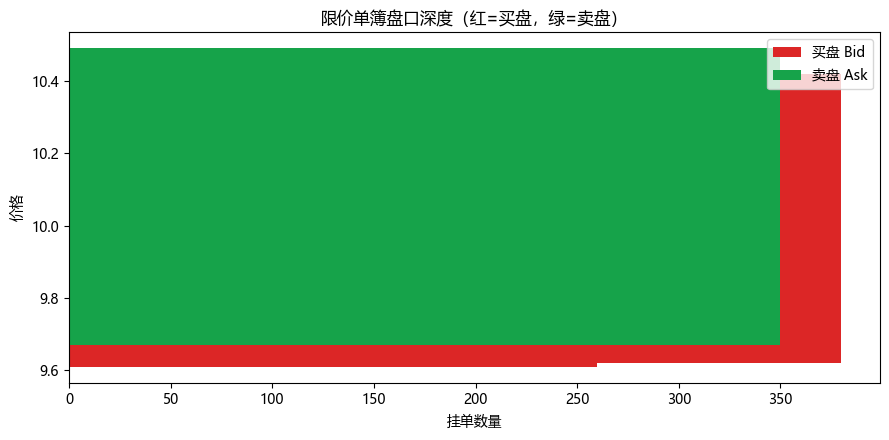

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
bid_d = ob.depth('bid', n_levels=5)
ask_d = ob.depth('ask', n_levels=5)
fig, ax = plt.subplots(figsize=(9, 4.5))
bp = [p for p, q in bid_d]; bq = [q for p, q in bid_d]
ap = [p for p, q in ask_d]; aq = [q for p, q in ask_d]
ax.barh(bp, bq, color='#dc2626', label='买盘 Bid')
ax.barh(ap, aq, color='#16a34a', label='卖盘 Ask')
ax.set_xlabel('挂单数量'); ax.set_ylabel('价格')
ax.set_title('限价单簿盘口深度（红=买盘，绿=卖盘）')
ax.legend(); plt.tight_layout(); plt.show()

## 五、主动方向识别（Tick Rule）

In [5]:
# 成交价上涨记为买方主动(+1)，下跌记为卖方主动(-1)，持平沿用前方向
import numpy as np
prices = np.array([10.00, 10.01, 10.01, 10.00, 9.99, 9.99, 10.00])
direction = np.sign(np.diff(prices, prepend=prices[0]))
for i in range(1, len(direction)):
    if direction[i] == 0:
        direction[i] = direction[i-1]
print('价格:', prices.tolist())
print('主动方向:', direction.tolist())

价格: [10.0, 10.01, 10.01, 10.0, 9.99, 9.99, 10.0]
主动方向: [0.0, 1.0, 1.0, -1.0, -1.0, -1.0, 1.0]


- 区分主动买/主动卖是计算订单流、OFI、VPIN 的基础；
- Tick rule：成交价较上一笔上升为买方主动，下降为卖方主动。

## 六、小结与面试要点

- 订单簿按价格档位挂单，连续竞价以价格优先、时间优先逐笔撮合。
- 主动订单吃对手盘，剩余挂单；盘口、价差、深度刻画流动性。
- Tick rule 用于识别主动买卖方向。

**面试高频：**
- 限价单如何撮合？（答：先与对手盘可成交档位逐档成交，剩余挂单，价格/时间优先）
- 订单簿的深度和价差分别反映什么？（答：深度反映可承接量，价差反映即时交易成本）
- 怎么判断一笔成交是买方还是卖方主动？（答：tick rule，看成交价相对上一笔的涨跌）
- 市价单和限价单的区别？（答：市价单即时成交可能滑点，限价单控制价格但可能不成交）

## 动手练习
1. 手动提交一笔跨多档的大买单，记录每档成交；
2. 画出某时刻的订单簿并标注中间价；
3. 用 tick rule 给一段成交序列标注主动方向。

---
下一节 **M1.4 微观结构指标**。